Numarul de clase este: 6
(35, 39, 3) ()
(23, 35, 3) ()
(26, 62, 3) ()
16 64
16 64


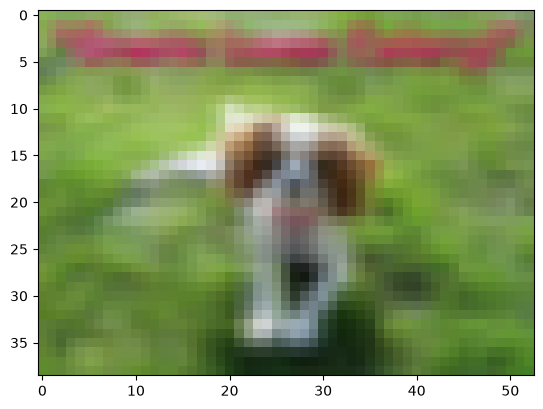

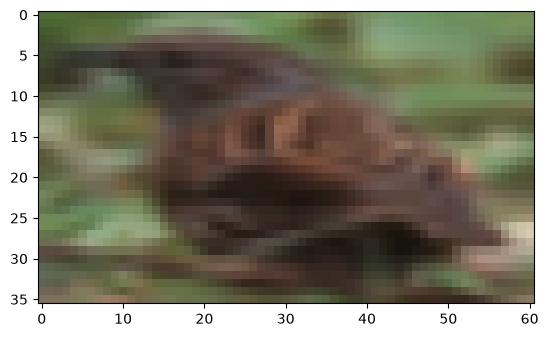

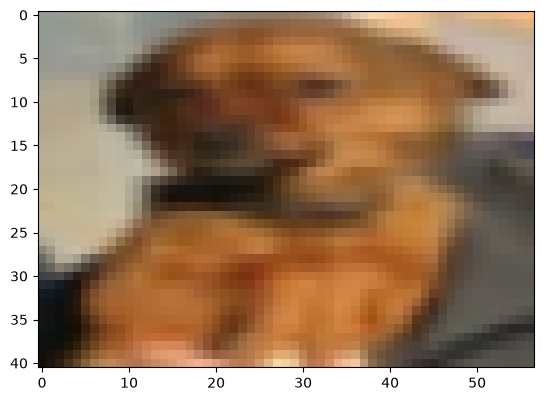

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchsummary import summary
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import torchvision
from PIL import Image

train_data = np.load('Numarul1-train/2_1_train.npz', allow_pickle=True)
x_train, y_train = train_data['x'], train_data['y']


test_data = np.load('Numarul1-test/2_1_test.npz', allow_pickle=True)
x_test, y_test = test_data['x'], test_data['y']

N_CLASSES = len(np.unique(y_train))
print(f"Numarul de clase este: {N_CLASSES}")

for i in range(3):
    print(x_train[np.random.randint(0, x_train.shape[0])].shape, y_train[np.random.randint(0, y_train.shape[0])].shape)
    plt.figure(), plt.imshow(x_train[np.random.randint(0, x_train.shape[0])], cmap='gray')

heigts = [img.shape[0] for img in x_train]
widths = [img.shape[1] for img in x_train]
print(min(heigts), max(heigts))
print(min(widths), max(widths))

# intre 16 si 64
H = 32


In [8]:
class CustomDataset(Dataset):
    def __init__(self, x, y):
        self.images = x
        self.labels = y

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = Image.fromarray(self.images[idx])
        label = self.labels[idx]

        image = image.resize(size=(H, H))
        image = torch.tensor(np.array(image), dtype=torch.float32)
        image = image / 255.0
        image = image.permute(2, 0, 1)

        label = torch.tensor(label, dtype=torch.int64)

        return image, label


train_dataset = CustomDataset(x_train, y_train)
test_dataset = CustomDataset(x_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

IN_FEATURES = H * H


In [9]:
class Model(nn.Module):
    def __init__(self, n_classes=N_CLASSES, act=nn.functional.relu):
        super().__init__()
        self.act = act

        # in -> (3, 32, 32)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1) # -> (32, 32, 32)
        self.pool1 = nn.MaxPool2d(2) # -> (32, 16, 16)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # -> (64, 16, 16)
        self.pool2 = nn.MaxPool2d(2) # -> (64, 8, 8)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, padding=1) # -> (64, 8, 8)
        self.pool3 = nn.MaxPool2d(2) # -> (64, 4, 4)

        self.fc1 = nn.Linear(64 * 4 * 4, 1024)
        self.fc2 = nn.Linear(1024, n_classes)

    def forward(self, x):
        x = self.pool1(self.act(self.conv1(x)))
        x = self.pool2(self.act(self.conv2(x)))
        x = self.pool3(self.act(self.conv3(x)))

        x = x.flatten(1) 
        x = self.act(self.fc1(x))
        x = self.fc2(x)                       

        return x


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Model().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
epochs = 10


def train(model, loader, optimizer, loss_fn, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (out.argmax(-1) == y).sum().item()
        total += y.size(0)
    return total_loss / len(loader), correct / total


def test(model, loader, loss_fn, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            total_loss += loss.item()
            correct += (out.argmax(-1) == y).sum().item()
            total += y.size(0)
        return total_loss / len(loader), correct / total

best = 0
for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train(model, train_loader, optimizer, loss_fn, device)
    test_loss, test_acc = test(model, test_loader, loss_fn, device)
    print(f"Epoch {epoch}: train loss={train_loss:.4f}, acc={train_acc:.4f} | test loss={test_loss:.4f}, acc={test_acc:.4f}")
    if best < test_acc:
        best = test_acc  
        torch.save(model, 'model.pt')


def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            correct += (out.argmax(-1) == y).sum().item()
            total += y.size(0)
        return correct / total


model = torch.load('model.pt', weights_only=False)
test_acc = evaluate(model, test_loader, device)
print(f'{test_acc:.4f}')



 10%|█         | 1/10 [00:04<00:41,  4.57s/it]

Epoch 0: train loss=1.1049, acc=0.5711 | test loss=0.8367, acc=0.6795


 20%|██        | 2/10 [00:08<00:35,  4.47s/it]

Epoch 1: train loss=0.7791, acc=0.7107 | test loss=0.7119, acc=0.7307


 30%|███       | 3/10 [00:13<00:32,  4.63s/it]

Epoch 2: train loss=0.6420, acc=0.7638 | test loss=0.6382, acc=0.7645


... (11 outputs left out)

Epoch 8: train loss=0.2413, acc=0.9121 | test loss=0.6081, acc=0.8083


100%|██████████| 10/10 [00:44<00:00,  4.44s/it]

Epoch 9: train loss=0.1831, acc=0.9343 | test loss=0.6375, acc=0.8135


0.8135
